# Regression
> We use the IXI dataset to predict age from T1-weighted brain MR images. The approach for regression tasks is nearly identical to classification, so take a look at the classification tutorial for explanations of the various cells.

[![Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MMIV-ML/fastMONAI/blob/main/nbs/11c_tutorial_regression.ipynb)

In [ ]:
#| hide
#Install `fastMONAI` if notebook is running on Google Colab
try:
    import google.colab
    %pip install fastMONAI
    from fastMONAI.utils import print_colab_gpu_info
    print_colab_gpu_info()
except:
    print('Running locally')

Running locally


In [ ]:
from fastMONAI.vision_all import *

In [ ]:
path = Path('../data')
path.mkdir(exist_ok=True)

In [ ]:
STUDY_DIR = download_ixi_data(path=path)

Images already downloaded and extracted to ../data/IXI/T1_images
2026-11-18 08:23:31,786 - INFO - Expected md5 is None, skip md5 check for file ../data/IXI/IXI.xls.


2026-11-18 08:23:31,787 - INFO - File exists: ../data/IXI/IXI.xls, skipped downloading.


Preprocessing ../data/IXI/IXI.xls


### Looking at the data

In [ ]:
df = pd.read_csv(STUDY_DIR/'dataset.csv')
df['age'] = np.around(df.age_at_scan.tolist(), decimals=0)

In [ ]:
df.head()

,t1_path,subject_id,gender,age_at_scan,age
0,../data/IXI/T1_images/IXI002-Guys-0828-T1.nii.gz,IXI002,F,35.80,36.0
1,../data/IXI/T1_images/IXI012-HH-1211-T1.nii.gz,IXI012,M,38.78,39.0
2,../data/IXI/T1_images/IXI013-HH-1212-T1.nii.gz,IXI013,M,46.71,47.0
3,../data/IXI/T1_images/IXI014-HH-1236-T1.nii.gz,IXI014,F,34.24,34.0
4,../data/IXI/T1_images/IXI015-HH-1258-T1.nii.gz,IXI015,M,24.28,24.0


In [ ]:
df.age.min(), df.age.max()

(np.float64(20.0), np.float64(86.0))

In [ ]:
med_dataset = MedDataset(path=STUDY_DIR/'T1_images', max_workers=12)

In [ ]:
data_info_df = med_dataset.summary()

In [ ]:
data_info_df.head()

,dim_0,dim_1,dim_2,voxel_0,voxel_1,voxel_2,orientation,example_path,total
3,150,256,256,1.2,0.9375,0.9375,RAS+,../data/IXI/T1_images/IXI002-Guys-0828-T1.nii.gz,498
2,146,256,256,1.2,0.9375,0.9375,RAS+,../data/IXI/T1_images/IXI035-IOP-0873-T1.nii.gz,74
4,150,256,256,1.2,0.9766,0.9766,RAS+,../data/IXI/T1_images/IXI297-Guys-0886-T1.nii.gz,5
0,130,256,256,1.2,0.9375,0.9375,RAS+,../data/IXI/T1_images/IXI023-Guys-0699-T1.nii.gz,2
1,140,256,256,1.2,0.9375,0.9375,RAS+,../data/IXI/T1_images/IXI020-Guys-0700-T1.nii.gz,2


In [ ]:
suggestion = med_dataset.get_suggestion()
target_spacing = suggestion['target_spacing']

In [ ]:
stats = med_dataset.get_size_statistics(target_spacing=target_spacing)
print(f"Image sizes (after resampling to {target_spacing}):")
print(f"  Min:    {stats['min']}")
print(f"  Median: {stats['median']}")
print(f"  Max:    {stats['max']}")

img_size = stats['max']
print(f"\nTarget size (max): {img_size}")

In [ ]:
bs=4
# Input shape for model architecture
in_shape = [1, 160, 256, 256]

In [ ]:
item_tfms = [ZNormalization(), PadOrCrop(in_shape[1:]), RandomAffine(scales=0, degrees=5, isotropic=False)] 

In [ ]:
dblock = MedDataBlock(blocks=(ImageBlock(cls=MedImage), RegressionBlock), 
                      splitter=RandomSplitter(seed=32),
                      get_x=ColReader('t1_path'),
                      get_y=ColReader('age'),
                      item_tfms=item_tfms,
                      apply_reorder=True,  # Reorder to RAS+ orientation (the common case)
                      target_spacing=target_spacing)

In [ ]:
dls = dblock.dataloaders(df, bs=bs)

In [ ]:
len(dls.train_ds.items), len(dls.valid_ds.items)

(449, 112)

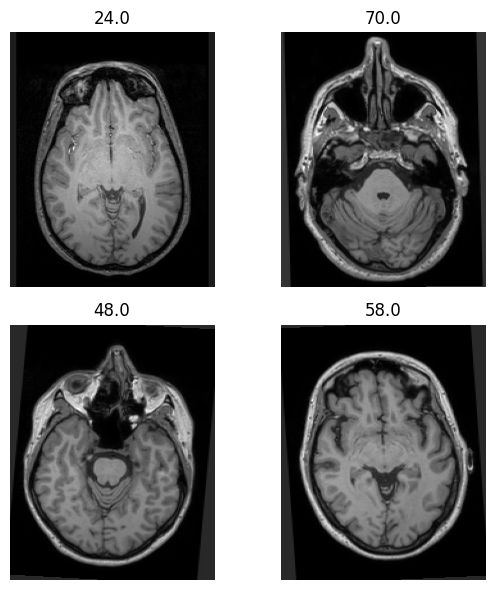

In [ ]:
dls.show_batch(anatomical_plane=2)

### Create and train a 3D model

Import a network from MONAI that can be used for regression tasks, and define the input image size, the output size, channels, etc.  

In [ ]:
from monai.networks.nets import Regressor
model = Regressor(in_shape=in_shape, out_shape=1, channels=(16, 32, 64, 128, 256),strides=(2, 2, 2, 2), kernel_size=3, num_res_units=2)

In [ ]:
loss_func = L1LossFlat()

In [ ]:
learn = Learner(dls, model, loss_func=loss_func, metrics=[mae])

In [ ]:
learn.summary()

Regressor (Input shape: 4 x 1 x 160 x 256 x 256)
Layer (type)         Output Shape         Param #    Trainable 
                     4 x 16 x 80 x 128 x 
Conv3d                                    448        True      
InstanceNorm3d                            0          False     
PReLU                                     1          True      
Conv3d                                    6928       True      
InstanceNorm3d                            0          False     
PReLU                                     1          True      
Conv3d                                    448        True      
____________________________________________________________________________
                     4 x 32 x 40 x 64 x  
Conv3d                                    13856      True      
InstanceNorm3d                            0          False     
PReLU                                     1          True      
Conv3d                                    27680      True      
InstanceNorm3d        

SuggestedLRs(valley=3.630780702224001e-05)

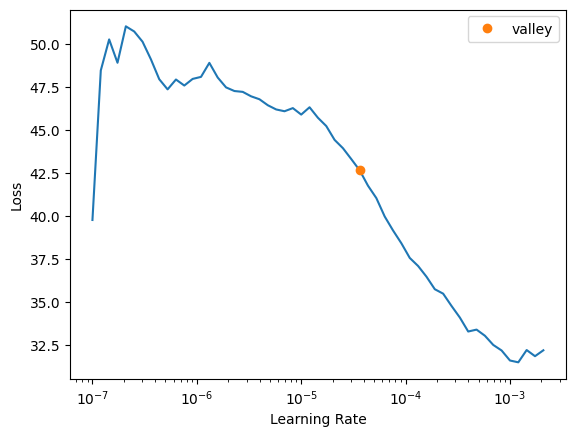

In [ ]:
learn.lr_find()

In [ ]:
lr = 1e-4

In [ ]:
from fastMONAI.utils import (
    create_mlflow_callback,
    make_model_spec,
    make_output_spec,
    standard_inference_config,
)
from fastMONAI.vision_augmentation import inference_transforms_to_specs

model_spec = make_model_spec('monai.regressor', {
    'in_shape': in_shape,
    'out_shape': 1,
    'channels': [16, 32, 64, 128, 256],
    'strides': [2, 2, 2, 2],
    'kernel_size': 3,
    'num_res_units': 2,
})
output_spec = make_output_spec('regression', output_shape=[1])
inference_config = standard_inference_config(
    apply_reorder=True,
    target_spacing=[float(v) for v in target_spacing],
    item_tfms=inference_transforms_to_specs(item_tfms),
    output_spec=output_spec,
)
mlflow_callback = create_mlflow_callback(
    learn,
    experiment_name='IXI_Age_Regression',
    model_spec=model_spec,
    inference_config=inference_config,
)
learn.fit_one_cycle(4, lr, cbs=[mlflow_callback])

In [ ]:
# Save model weights for learn.load(...); continued training creates a fresh optimizer.
learn.save('brainage-weights', with_opt=False)

### Inference

In [ ]:
learn.load('brainage-weights', with_opt=False); 

In [ ]:
interp = Interpretation.from_learner(learn)

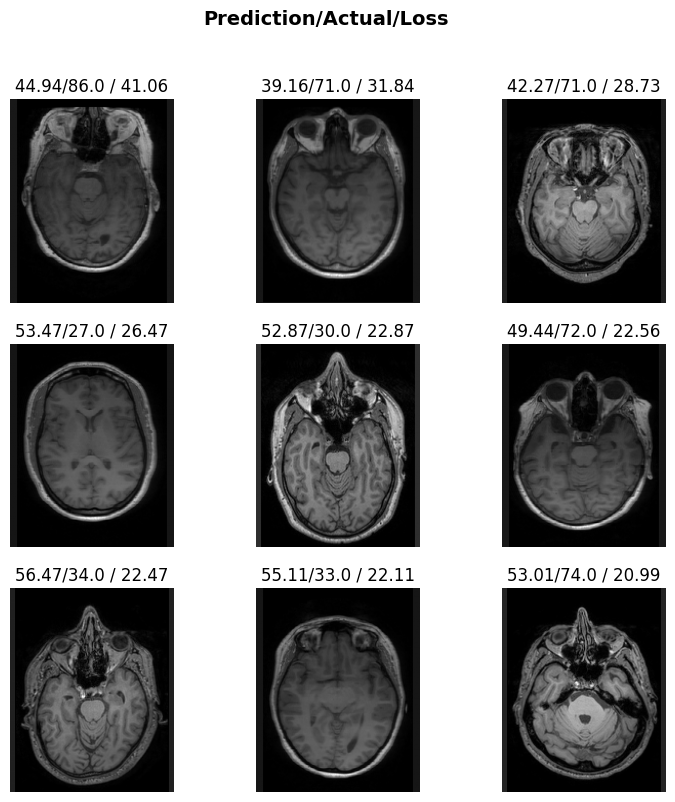

In [ ]:
interp.plot_top_losses(k=9, anatomical_plane=2)